In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

## Loading **Dataset**

In [2]:
df = pd.read_csv(r'data/credit_risk_dataset.csv')
df.head(3)

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3


## **EDA** & **Cleaning**

In [3]:
print(f'''
Number of Rows: {df.shape[0]}
Number of Columns: {df.shape[1]}
''')


Number of Rows: 32581
Number of Columns: 12



In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32581 entries, 0 to 32580
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   person_age                  32581 non-null  int64  
 1   person_income               32581 non-null  int64  
 2   person_home_ownership       32581 non-null  object 
 3   person_emp_length           31686 non-null  float64
 4   loan_intent                 32581 non-null  object 
 5   loan_grade                  32581 non-null  object 
 6   loan_amnt                   32581 non-null  int64  
 7   loan_int_rate               29465 non-null  float64
 8   loan_status                 32581 non-null  int64  
 9   loan_percent_income         32581 non-null  float64
 10  cb_person_default_on_file   32581 non-null  object 
 11  cb_person_cred_hist_length  32581 non-null  int64  
dtypes: float64(3), int64(5), object(4)
memory usage: 3.0+ MB


In [5]:
df.duplicated().sum()

np.int64(165)

In [6]:
df.drop_duplicates(inplace = True)

In [7]:
df.isnull().sum()[df.isnull().sum().values > 0]

person_emp_length     887
loan_int_rate        3095
dtype: int64

In [8]:
round(df[['person_emp_length', 'loan_int_rate']].isnull().sum() * 100/df.shape[0], 2)

person_emp_length    2.74
loan_int_rate        9.55
dtype: float64

In [9]:
df[['person_emp_length', 'loan_int_rate']].head()

,person_emp_length,loan_int_rate
0,123.0,16.02
1,5.0,11.14
2,1.0,12.87
3,4.0,15.23
4,8.0,14.27


In [10]:
df[['person_emp_length', 'loan_int_rate']].describe()

,person_emp_length,loan_int_rate
count,31529.00000,29321.000000
mean,4.79051,11.017265
std,4.14549,3.241680
min,0.00000,5.420000
25%,2.00000,7.900000
50%,4.00000,10.990000
75%,7.00000,13.470000
max,123.00000,23.220000


In [11]:
mean_a, mean_b = round(df[['person_emp_length', 'loan_int_rate']].mean(), 2)
median_a, median_b = round(df[['person_emp_length', 'loan_int_rate']].median(), 2)
print(f'''
  person_emp_length (mean) : {mean_a}
  person_emp_length (median) : {median_a}
  loan_int_rate (mean) : {mean_b}
  loan_int_rate (median) : {median_b}
''')


  person_emp_length (mean) : 4.79
  person_emp_length (median) : 4.0
  loan_int_rate (mean) : 11.02
  loan_int_rate (median) : 10.99



In [12]:
df[['person_emp_length', 'loan_int_rate']] = df[['person_emp_length', 'loan_int_rate']].fillna(df[['person_emp_length', 'loan_int_rate']].mean())

In [13]:
df[['person_emp_length', 'loan_int_rate']].isnull().sum()

person_emp_length    0
loan_int_rate        0
dtype: int64

In [14]:
numerical_columns = df.select_dtypes(include = np.number).columns.to_list()
print(f'Lenght of Numerical Columns: {len(numerical_columns)}')
print(f'Numerical Columns: {numerical_columns}')

Lenght of Numerical Columns: 8
Numerical Columns: ['person_age', 'person_income', 'person_emp_length', 'loan_amnt', 'loan_int_rate', 'loan_status', 'loan_percent_income', 'cb_person_cred_hist_length']


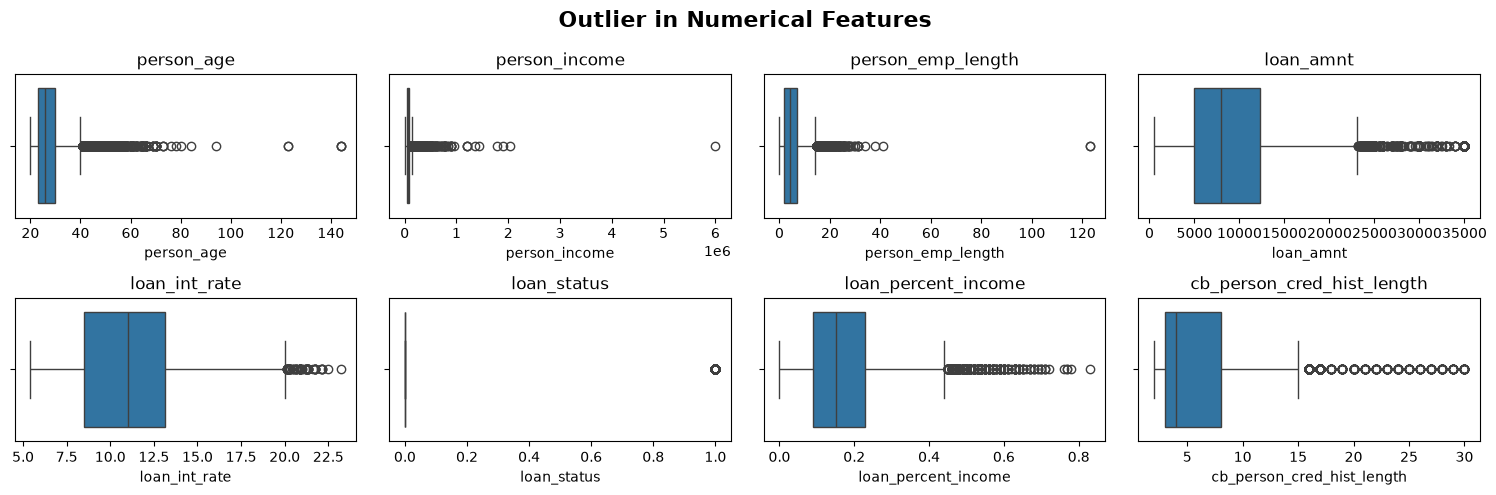

In [15]:
fig, axes = plt.subplots(nrows = 2, ncols = 4, figsize = (15, 5))
axes = axes.flatten()

for i, column in enumerate(numerical_columns):
  ax = axes[i]
  sns.boxplot(
      data = df,
      x = column,
      ax = ax
    )
  axes[i].set_title(column)

fig.suptitle('Outlier in Numerical Features', fontsize = 16, weight = 'bold')
plt.tight_layout()
plt.show()

In [16]:
df[df['person_age'] > 100]

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
81,144,250000,RENT,4.0,VENTURE,C,4800,13.570000,0,0.02,N,3
183,144,200000,MORTGAGE,4.0,EDUCATION,B,6000,11.860000,0,0.03,N,2
575,123,80004,RENT,2.0,EDUCATION,B,20400,10.250000,0,0.25,N,3
747,123,78000,RENT,7.0,VENTURE,B,20000,11.017265,0,0.26,N,4
32297,144,6000000,MORTGAGE,12.0,PERSONAL,C,5000,12.730000,0,0.00,N,25


In [17]:
df = df[~(df['person_age'] > 100)]

In [18]:
df = df[~(df['person_emp_length'] > 70)]

In [19]:
df[df['person_emp_length'] >= df['person_age'] - 14]

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length


In [20]:
df[numerical_columns].skew()

person_age                    1.942359
person_income                 9.777874
person_emp_length             1.266911
loan_amnt                     1.191489
loan_int_rate                 0.217773
loan_status                   1.361056
loan_percent_income           1.063283
cb_person_cred_hist_length    1.657991
dtype: float64

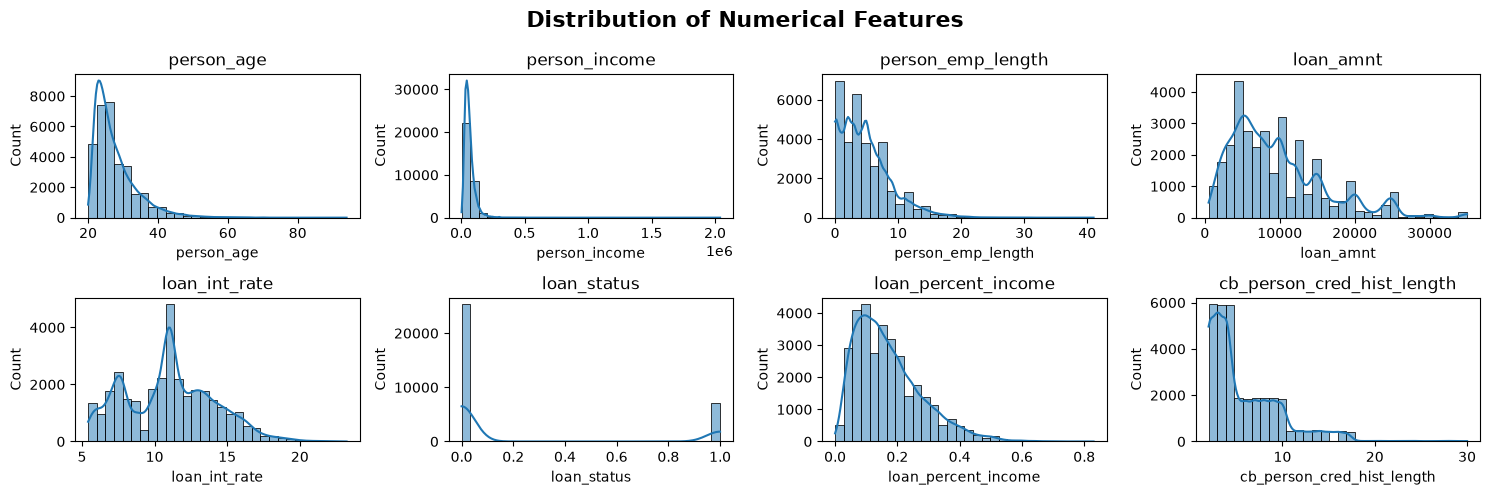

In [21]:
fig, axes = plt.subplots(nrows = 2, ncols = 4, figsize = (15, 5))
axes = axes.flatten()

for i, column in enumerate(numerical_columns):
  ax = axes[i]
  sns.histplot(
      data = df,
      x = column,
      ax = ax,
      kde = True,
      bins = 30
    )
  axes[i].set_title(column)

fig.suptitle('Distribution of Numerical Features', fontsize = 16, weight = 'bold')
plt.tight_layout()
plt.show()

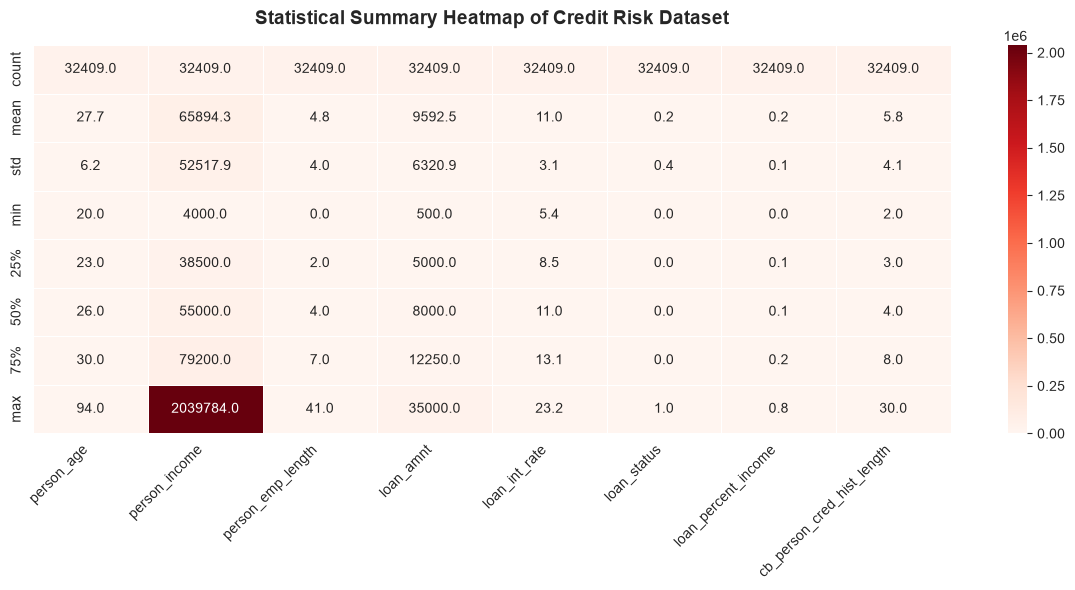

In [22]:
plt.figure(figsize=(12, 6))
sns.set_style('whitegrid')

stats_df = df.describe(include = np.number).T

sns.heatmap(
    df.describe(include = np.number),
    annot = True,
    fmt = ".1f",
    cmap = "Reds",
    linewidths = 0.5,
    cbar = True
)
plt.title("Statistical Summary Heatmap of Credit Risk Dataset", fontsize = 14, fontweight = 'bold', pad = 15)
plt.xticks(rotation = 45, ha = 'right', fontsize = 10)
plt.yticks(fontsize = 10)

plt.tight_layout()
plt.show()

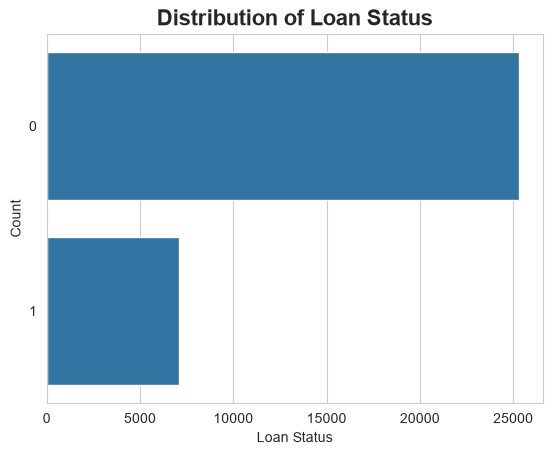

In [23]:
sns.countplot(
    data = df,
    y = 'loan_status'
)
plt.title(
    'Distribution of Loan Status',
    fontsize = 16,
    fontweight = 'bold'
)
plt.xlabel('Loan Status')
plt.ylabel('Count')
plt.show()

In [24]:
df.columns

Index(['person_age', 'person_income', 'person_home_ownership',
       'person_emp_length', 'loan_intent', 'loan_grade', 'loan_amnt',
       'loan_int_rate', 'loan_status', 'loan_percent_income',
       'cb_person_default_on_file', 'cb_person_cred_hist_length'],
      dtype='object')

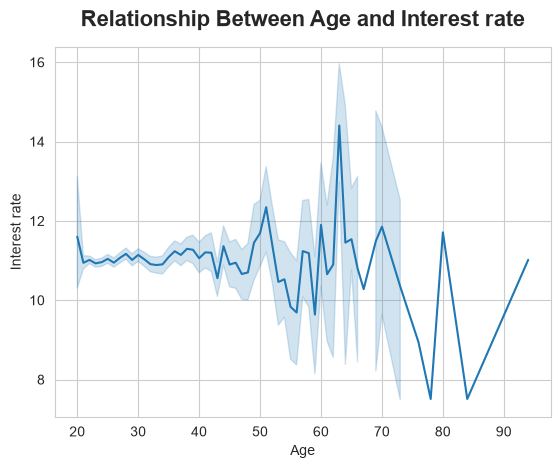

In [25]:
sns.lineplot(data = df, x = 'person_age', y = 'loan_int_rate')
plt.title(
    'Relationship Between Age and Interest rate',
    fontsize = 16,
    fontweight = 'bold',
    pad = 15
)
plt.xlabel('Age')
plt.ylabel('Interest rate')
plt.show()

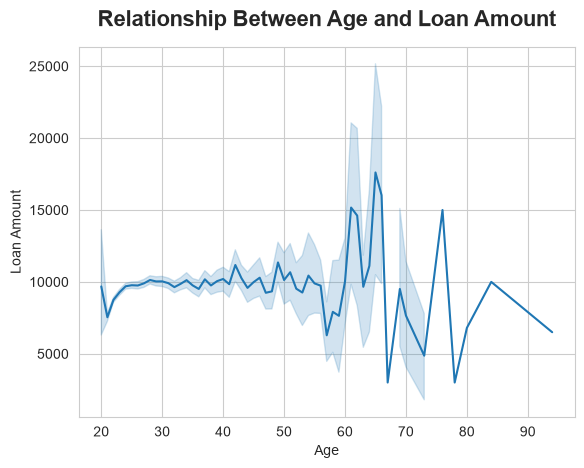

In [26]:
sns.lineplot(data = df, x = 'person_age', y = 'loan_amnt')
plt.title(
    'Relationship Between Age and Loan Amount',
    fontsize = 16,
    fontweight = 'bold',
    pad = 15
)
plt.xlabel('Age')
plt.ylabel('Loan Amount')
plt.show()

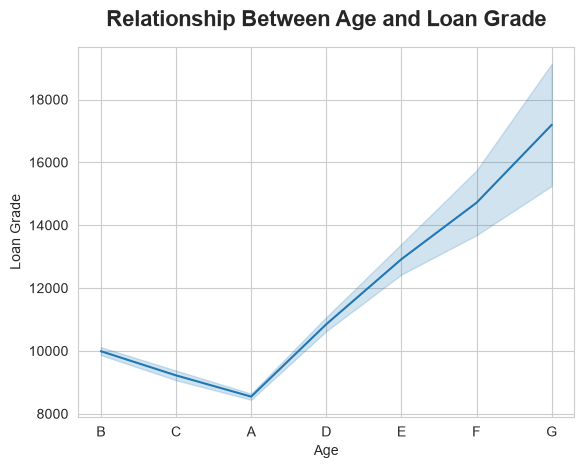

In [27]:
sns.lineplot(data = df, x = 'loan_grade', y = 'loan_amnt')
plt.title(
    'Relationship Between Age and Loan Grade',
    fontsize = 16,
    fontweight = 'bold',
    pad = 15
)
plt.xlabel('Age')
plt.ylabel('Loan Grade')
plt.show()

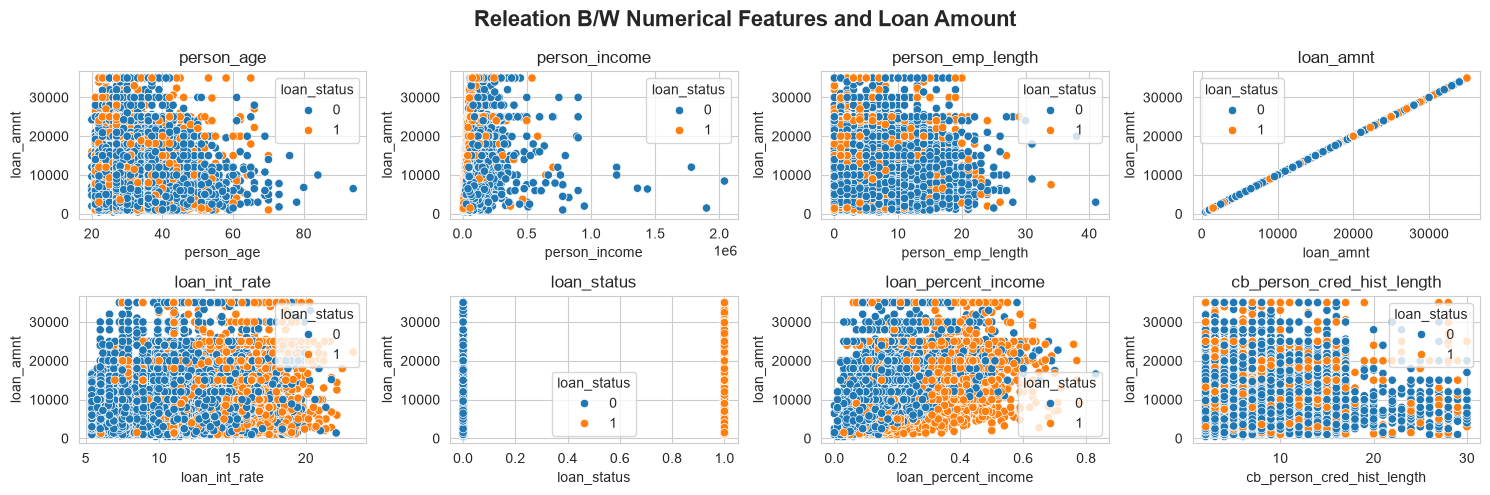

In [28]:
fig, axes = plt.subplots(nrows = 2, ncols = 4, figsize = (15, 5))
axes = axes.flatten()

for i, column in enumerate(numerical_columns):
  ax = axes[i]
  sns.scatterplot(
      data = df,
      x = column,
      y = 'loan_amnt',
      hue = 'loan_status',
      ax = ax,
    )
  axes[i].set_title(column)

fig.suptitle('Releation B/W Numerical Features and Loan Amount', fontsize = 16, weight = 'bold')
plt.tight_layout()
plt.show()

In [29]:
categorical_columns = df.select_dtypes(exclude = np.number).columns.to_list()
print(f'Lenght of Categorical Columns: {len(categorical_columns)}')
print(f'Categorical Columns: {categorical_columns}')

Lenght of Categorical Columns: 4
Categorical Columns: ['person_home_ownership', 'loan_intent', 'loan_grade', 'cb_person_default_on_file']


<function matplotlib.pyplot.show(close=None, block=None)>

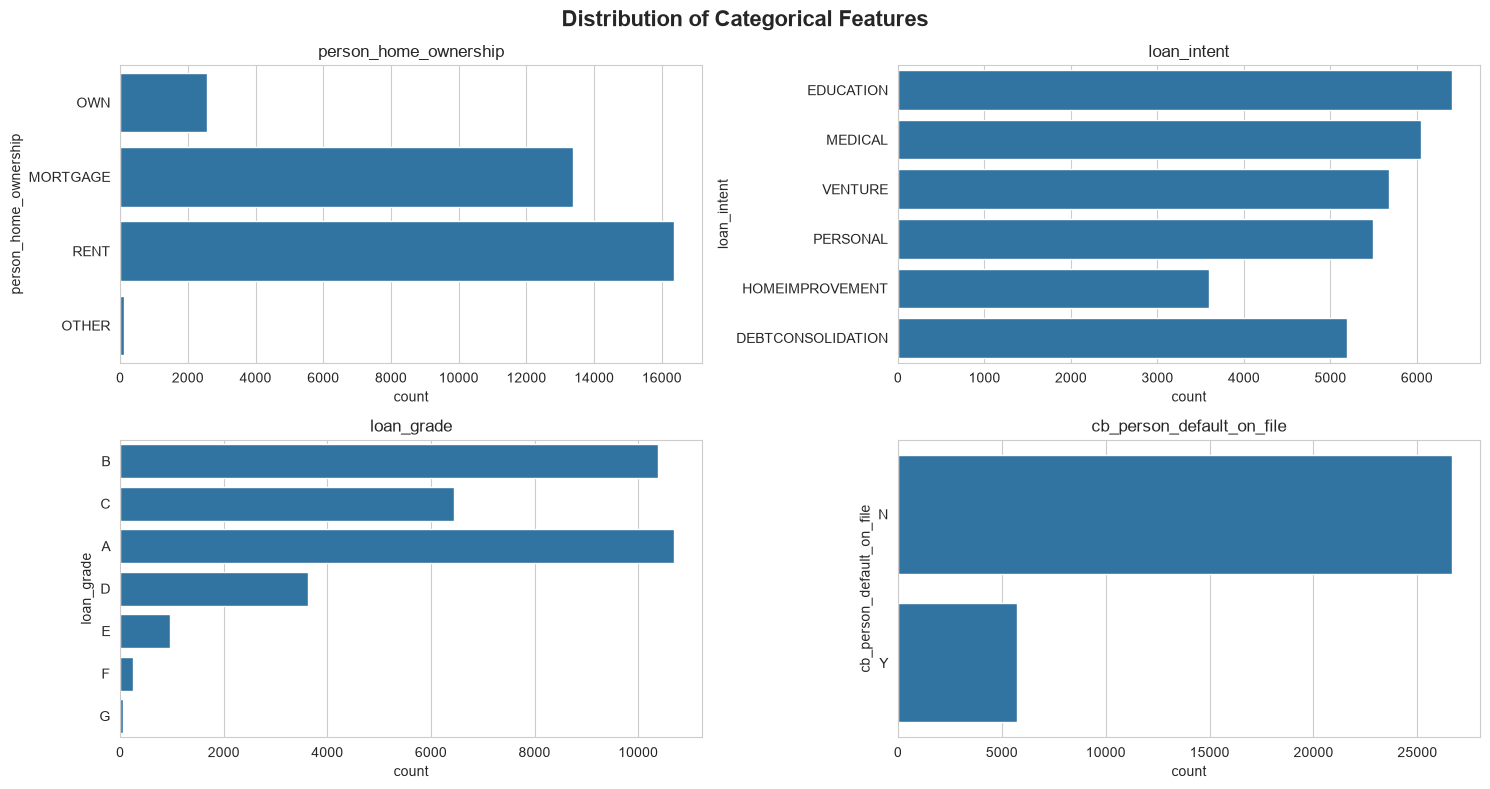

In [30]:
fig, axes = plt.subplots(nrows = 2, ncols = 2, figsize = (15, 8))
axes = axes.flatten()

for i, column in enumerate(categorical_columns):
  ax = axes[i]
  sns.countplot(
      data = df,
      y = column,
      ax = ax
    )
  axes[i].set_title(column)

fig.suptitle('Distribution of Categorical Features', fontsize = 16, weight = 'bold')
plt.tight_layout()
plt.show

<function matplotlib.pyplot.show(close=None, block=None)>

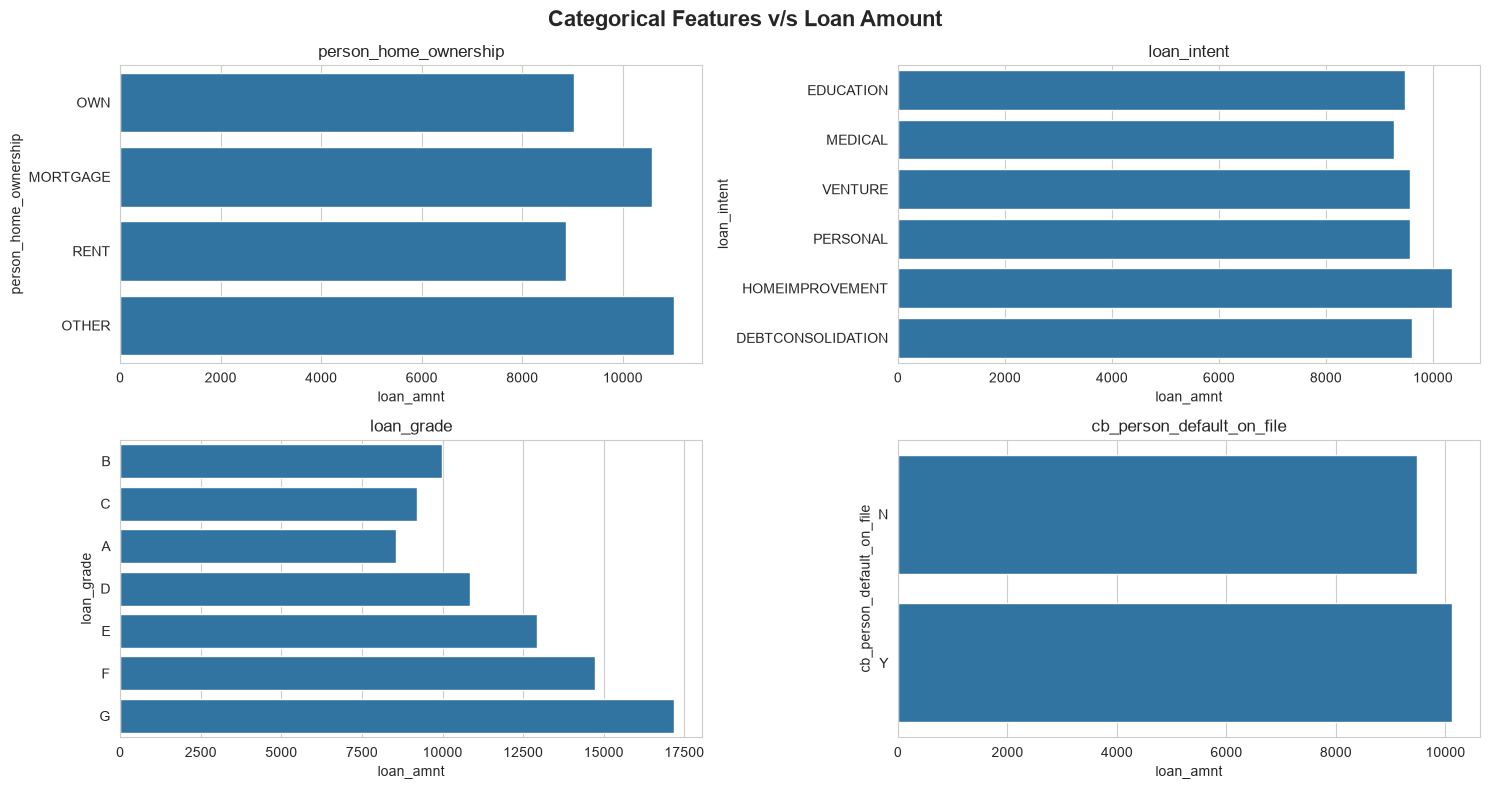

In [31]:
fig, axes = plt.subplots(nrows = 2, ncols = 2, figsize = (15, 8))
axes = axes.flatten()

for i, column in enumerate(categorical_columns):
  ax = axes[i]
  sns.barplot(
      data = df,
      y = column,
      x = 'loan_amnt',
      ax = ax,
      errorbar = None,
    )
  axes[i].set_title(column)

fig.suptitle('Categorical Features v/s Loan Amount', fontsize = 16, weight = 'bold')
plt.tight_layout()
plt.show

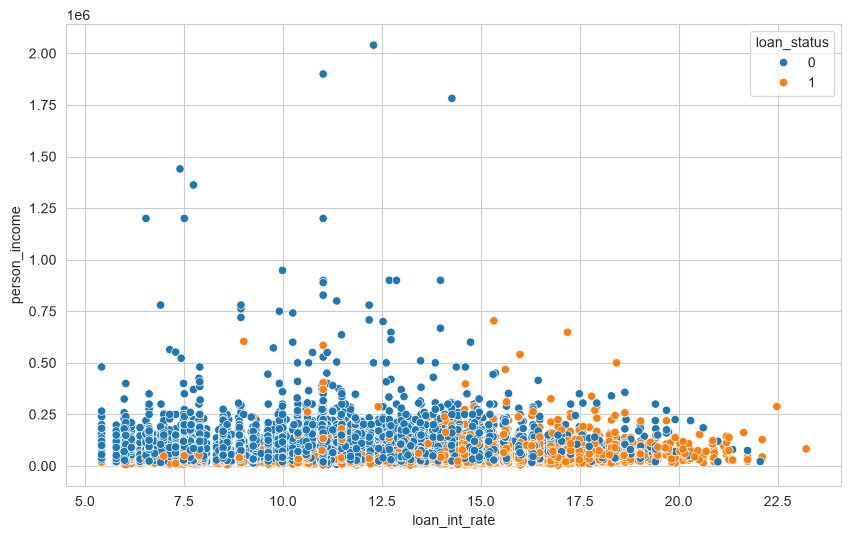

In [32]:
plt.figure(figsize = (10, 6))
sns.scatterplot(
    data = df,
    x = 'loan_int_rate',
    y = 'person_income',
    hue = 'loan_status'
)
plt.show()

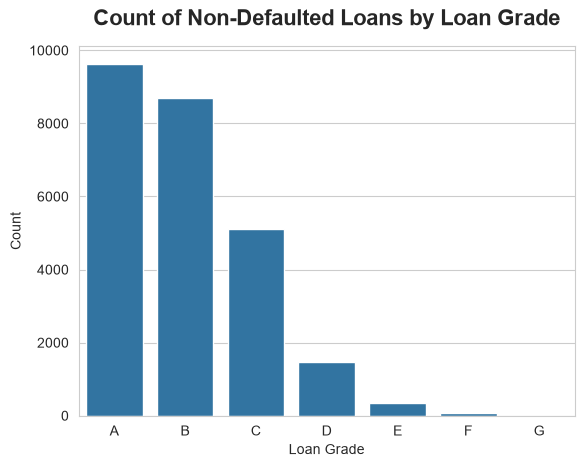

In [33]:
loan_status_by_grade = pd.DataFrame(df[df['loan_status'] == 0].groupby('loan_grade')['loan_status'].count().sort_index(), columns = ['loan_status'])
loan_status_by_grade['loan_status'] = loan_status_by_grade['loan_status'].astype(int)
sns.barplot(
    data = loan_status_by_grade,
    x = loan_status_by_grade.index,
    y = loan_status_by_grade['loan_status']
)
plt.title(
    'Count of Non-Defaulted Loans by Loan Grade',
    fontsize = 16,
    fontweight = 'bold',
    pad = 15
)
plt.xlabel('Loan Grade')
plt.ylabel('Count')
plt.show()

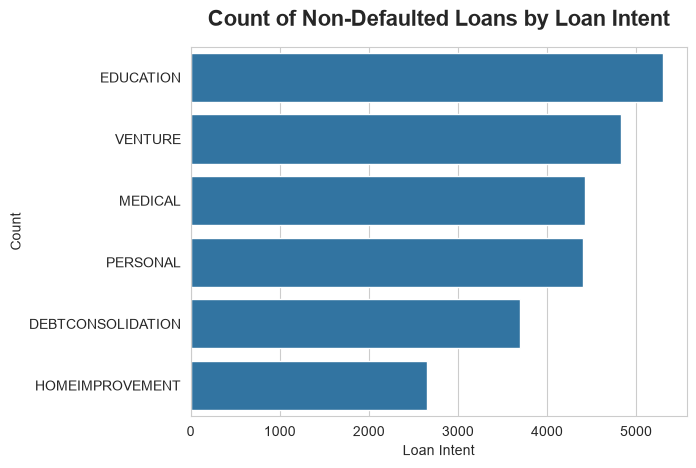

In [34]:
loan_status_by_grade = pd.DataFrame(df[df['loan_status'] == 0].groupby('loan_intent')['loan_status'].count().sort_values(ascending = False), columns = ['loan_status'])
loan_status_by_grade['loan_status'] = loan_status_by_grade['loan_status'].astype(int)
sns.barplot(
    data = loan_status_by_grade,
    y = loan_status_by_grade.index,
    x = loan_status_by_grade['loan_status']
)
plt.title(
    'Count of Non-Defaulted Loans by Loan Intent',
    fontsize = 16,
    fontweight = 'bold',
    pad = 15
)
plt.xlabel('Loan Intent')
plt.ylabel('Count')
plt.show()

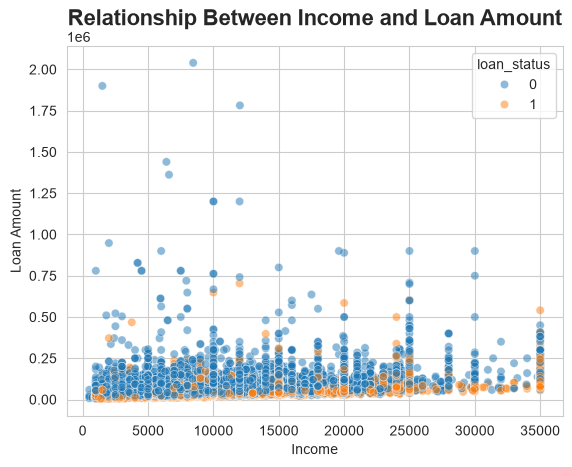

In [35]:
sns.scatterplot(
    data = df,
    y = 'person_income',
    x = 'loan_amnt',
    hue = 'loan_status',
    alpha = 0.5
)
plt.title(
    'Relationship Between Income and Loan Amount',
    fontsize = 16,
    fontweight = 'bold',
    pad = 15
)
plt.xlabel('Income')
plt.ylabel('Loan Amount')
plt.show()

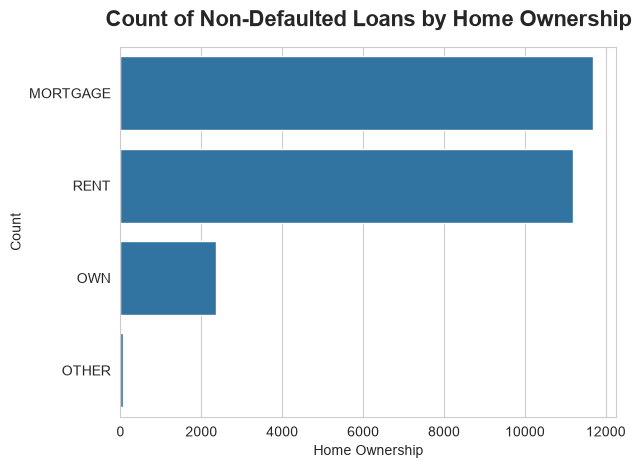

In [36]:
loan_status_by_grade = pd.DataFrame(df[df['loan_status'] == 0].groupby('person_home_ownership')['loan_status'].count().sort_values(ascending = False), columns = ['loan_status'])
loan_status_by_grade['loan_status'] = loan_status_by_grade['loan_status'].astype(int)
sns.barplot(
    data = loan_status_by_grade,
    y = loan_status_by_grade.index,
    x = loan_status_by_grade['loan_status']
)
plt.title(
    'Count of Non-Defaulted Loans by Home Ownership',
    fontsize = 16,
    fontweight = 'bold',
    pad = 15
)
plt.xlabel('Home Ownership')
plt.ylabel('Count')
plt.show()

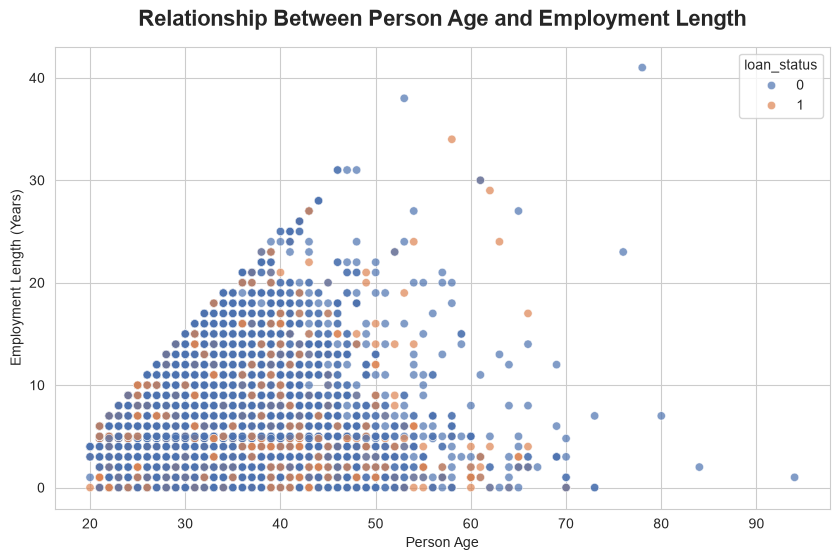

In [37]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x='person_age',
    y='person_emp_length',
    hue='loan_status',
    alpha=0.7,
    palette='deep'
)

plt.title(
    'Relationship Between Person Age and Employment Length',
    fontsize=16,
    fontweight='bold',
    pad=15
)
plt.xlabel('Person Age')
plt.ylabel('Employment Length (Years)')
plt.show()

## **Feature**, **Target** & **Train-Test-Split**

In [38]:
X = df.drop(columns = ['loan_status'])
y = df['loan_status']

In [39]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 42, stratify = y)

In [40]:
numerical_columns = X_train.select_dtypes(include = np.number).columns.to_list()
categorical_columns = X_train.select_dtypes(exclude = np.number).columns.to_list()

print(f'Lenght of Numerical Columns: {len(numerical_columns)}')
print(f'Lenght of Categorical Columns: {len(categorical_columns)}')

Lenght of Numerical Columns: 7
Lenght of Categorical Columns: 4


## **Class Imbelance Handling**

In [41]:
neg, pos = np.bincount(y_train)
scale_weights = neg / pos
print(f'Scale Weights: {scale_weights}')

Scale Weights: 3.572663139329806


## **Data preprocessing** - **Column Transform**, **Pipeline**

In [42]:
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.preprocessing import FunctionTransformer
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

In [43]:
X_train[numerical_columns].skew()

person_age                    1.908786
person_income                 9.634483
person_emp_length             1.238364
loan_amnt                     1.186876
loan_int_rate                 0.218344
loan_percent_income           1.065134
cb_person_cred_hist_length    1.657087
dtype: float64

In [44]:
skewed_columns = ['person_income','person_age', 'cb_person_cred_hist_length']
scaled_columns = X_test[numerical_columns].drop(columns = skewed_columns).columns

print(f'Lenght of Skewed Columns: {len(skewed_columns)}')
print(f'Lenght of Scaled Columns: {len(scaled_columns)}')
print(f'Lenght of Categorical Columns: {len(categorical_columns)}')

Lenght of Skewed Columns: 3
Lenght of Scaled Columns: 4
Lenght of Categorical Columns: 4


### Preprocessing for **Logistic Reggression**

In [45]:
preprocessor_lr = ColumnTransformer(transformers = [

    ('skew', Pipeline(steps = [
        ('imputer', SimpleImputer(strategy = 'median')),
        ('scaler', FunctionTransformer(np.log1p)),
    ]), skewed_columns),

    ('scale', Pipeline(steps = [
        ('imputer', SimpleImputer(strategy = 'median')),
        ('scaler', StandardScaler()),
    ]), scaled_columns),

    ('onehot', Pipeline(steps = [
        ('imputer', SimpleImputer(strategy = 'most_frequent')),
        ('encoder', OneHotEncoder(handle_unknown = 'ignore')),
    ]), categorical_columns)

])
preprocessor_lr

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('skew', ...), ('scale', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``featur

### Preprocessing for **XGBoast**

In [46]:
preprocessor_xgb = ColumnTransformer(transformers = [

    ('skew', Pipeline(steps = [
        ('imputer', SimpleImputer(strategy = 'median')),
        ('scaler', FunctionTransformer(np.log1p)),
    ]), skewed_columns),

    ('scale', Pipeline(steps = [
        ('imputer', SimpleImputer(strategy = 'median')),
    ]), scaled_columns),

    ('onehot', Pipeline(steps = [
        ('imputer', SimpleImputer(strategy = 'most_frequent')),
        ('encoder', OneHotEncoder(handle_unknown = 'ignore')),
    ]), categorical_columns)

])
preprocessor_xgb

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('skew', ...), ('scale', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``featur

## Stratified **Cross Validation**

In [47]:
from sklearn.model_selection import StratifiedKFold
cv = StratifiedKFold(n_splits = 5, shuffle = True, random_state = 42)

scoring = {
    'roc_auc':'roc_auc',
    'accuracy':'accuracy',
    'precision':'precision',
    'recall':'recall',
    'f1':'f1'
}

In [48]:
# LogisticRegression
from sklearn.linear_model import LogisticRegression
lr = LogisticRegression(max_iter = 1000, random_state = 44, class_weight = 'balanced')

lr_model = Pipeline(steps = [
    ('preprocessor' , preprocessor_lr),
    ('classifier' , lr)
])

In [49]:
# XGBoast
from xgboost import XGBClassifier
xgb = XGBClassifier(
    random_state = 44,
    n_estimators = 300,
    learning_rate = 0.1,
    max_depth = 5,
    scale_pos_weight = scale_weights,
)

xgb_model = Pipeline(steps = [
    ('preprocessor', preprocessor_xgb),
    ('classifier', xgb)
])

In [50]:
from sklearn.model_selection import cross_validate

models = {
    'Logistic Regression' : lr_model,
    'XGBoast' : xgb_model
}

for model_name, model_pipeline in models.items():
  cv_result = cross_validate(
      model_pipeline,
      X_train,
      y_train,
      cv = cv,
      scoring = scoring,
      n_jobs = -1
  )

  print(f'Model: {model_name}')
  print(f'ROC AUC: {cv_result["test_roc_auc"].mean()}')
  print(f'Accuracy: {cv_result["test_accuracy"].mean()}')
  print(f'Precision: {cv_result["test_precision"].mean()}')
  print(f'Recall: {cv_result["test_recall"].mean()}')
  print(f'F1 Score: {cv_result["test_f1"].mean()}')
  print()

Model: Logistic Regression
ROC AUC: 0.8758138297371396
Accuracy: 0.8098117288553375
Precision: 0.544922376097414
Recall: 0.7918871252204586
F1 Score: 0.6455634157802514

Model: XGBoast
ROC AUC: 0.9465071157760552
Accuracy: 0.9170746252892867
Precision: 0.8209408969327046
Recall: 0.7941798941798941
F1 Score: 0.8073099749301254



## **Evaluation** Helper Function

In [51]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, classification_report
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import precision_recall_curve, roc_curve

def evaluate_model(model_name, estimator, training_features, training_labels, testing_features, testing_labels, param_grid = None, cv = 5, threshould = None):
  if model_name:
    print(f'Model: {model_name}')
    if param_grid:
      model = RandomizedSearchCV(
          estimator = estimator,
          param_distributions = param_grid,
          n_iter = 10,
          cv = cv,
          scoring = 'roc_auc',
          n_jobs = -1,
          verbose = 1,
          random_state = 42
      )
      model.fit(training_features, training_labels)
      print(f'Best Parameters: {model.best_params_}')
      print(f'Best Score: {model.best_score_}')
    else:
      model = estimator
      model.fit(training_features, training_labels)

    y_pred_proba_test = model.predict_proba(testing_features)[:, 1]
    y_pred_proba_train = model.predict_proba(training_features)[:, 1]

    if threshould:
      y_pred_test = (y_pred_proba_test >= threshould).astype(int)
      y_pred_train = (y_pred_proba_train >= threshould).astype(int)
    else:
      y_pred_test = model.predict(testing_features)
      y_pred_train = model.predict(training_features)

    # Metrics
    # Accuracy score
    accuracy_test = accuracy_score(testing_labels, y_pred_test)
    accuracy_train = accuracy_score(training_labels, y_pred_train)
    # Precision & Recall
    precision_test = precision_score(testing_labels, y_pred_test)
    precision_train = precision_score(training_labels, y_pred_train)
    recall_test = recall_score(testing_labels, y_pred_test)
    recall_train = recall_score(training_labels, y_pred_train)
    # F1 score
    f1_test = f1_score(testing_labels, y_pred_test)
    f1_train = f1_score(training_labels, y_pred_train)
    #ROC-AUC score
    roc_auc_test = roc_auc_score(testing_labels, y_pred_test)
    roc_auc_train = roc_auc_score(training_labels, y_pred_train)

    print('\n\n')

    # Confusion matrix Ploting
    confusion_matrix_test = confusion_matrix(testing_labels, y_pred_test)
    confusion_matrix_train = confusion_matrix(training_labels, y_pred_train)
    plt.subplot(2, 1, 1)
    sns.heatmap(
        data = confusion_matrix_test,
        annot = True,
        fmt = 'd',
        cmap = 'Blues',
    )
    plt.title('Confusion Matrix for Test Data')
    plt.subplot(2, 1, 2)
    sns.heatmap(
        data = confusion_matrix_train,
        annot = True,
        fmt = 'd',
        cmap = 'Blues',
    )
    plt.title('Confusion Matrix for Train Data')
    plt.tight_layout()
    plt.show()

    print('\n\n')

    # ROC-AUC curve plotting

    plt.subplot(2, 1, 1)
    fpr_test, tpr_test, _ = roc_curve(testing_labels, model.predict_proba(testing_features)[:, 1])
    plt.plot(fpr_test, tpr_test, label = 'Test Data')
    fpr_train, tpr_train, _ = roc_curve(training_labels, model.predict_proba(training_features)[:, 1])
    plt.plot(fpr_train, tpr_train, label = 'Train Data')
    plt.plot([0, 1], [0, 1], linestyle = '--', color = 'black')
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('ROC Curve')
    plt.legend()

    plt.subplot(2, 1, 2)
    precision_t, recall_t, threshold = precision_recall_curve(testing_labels, model.predict_proba(testing_features)[:, 1])
    plt.plot(recall_t, precision_t, label = 'Test Data')
    precision_tr, recall_tr, threshold = precision_recall_curve(training_labels, model.predict_proba(training_features)[:, 1])
    plt.plot(recall_tr, precision_tr, label = 'Train Data')
    plt.xlabel('Recall')
    plt.ylabel('Precision')
    plt.title('Precision-Recall Curve')
    plt.legend()
    plt.show()

    print('\n\n')

    # Classification Report
    print('Classification Report for Test Data')
    print(classification_report(testing_labels, y_pred_test))
    print('\nClassification Report for Train Data')
    print(classification_report(training_labels, y_pred_train))

    print('\n\n')

    metrics_data = {
        'Metric': [
            'Accuracy_test', 'Precision_test', 'Recall_test', 'F1 Score_test', 'ROC-AUC_test',
            'Accuracy_train', 'Precision_train', 'Recall_train', 'F1 Score_train', 'ROC-AUC_train'
        ],
        model_name: [
            accuracy_test, precision_test, recall_test, f1_test, roc_auc_test,
            accuracy_train, precision_train, recall_train, f1_train, roc_auc_train
        ]
    }
    df_metrics = pd.DataFrame(metrics_data)
    df_metrics.set_index('Metric', inplace = True)

    display(df_metrics)

    return df_metrics, model
  else:
    raise ValueError('Required parameters is not required')

## Baseline Model - **LogisticReggression**

In [52]:
baseline_model = Pipeline(steps = [
    ('Preprocessor' , preprocessor_lr),
    ('Classifier', LogisticRegression(class_weight = 'balanced'))
])

Model: Logistic Regression





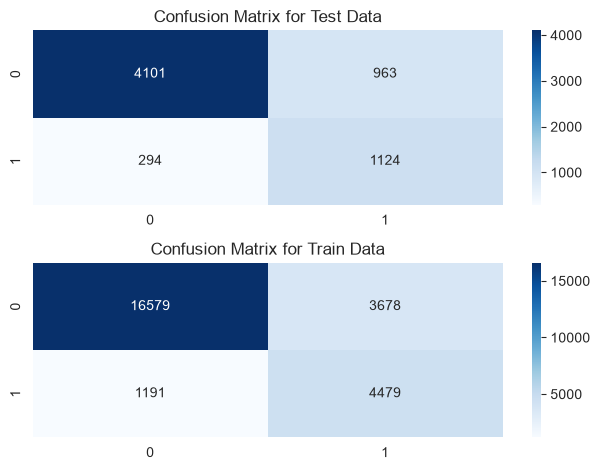

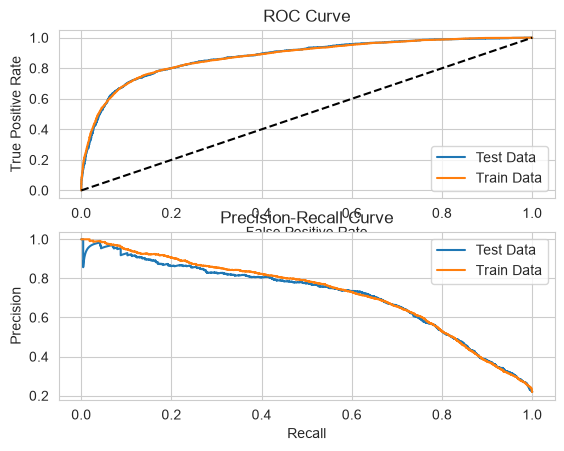




Classification Report for Test Data
              precision    recall  f1-score   support

           0       0.93      0.81      0.87      5064
           1       0.54      0.79      0.64      1418

    accuracy                           0.81      6482
   macro avg       0.74      0.80      0.75      6482
weighted avg       0.85      0.81      0.82      6482


Classification Report for Train Data
              precision    recall  f1-score   support

           0       0.93      0.82      0.87     20257
           1       0.55      0.79      0.65      5670

    accuracy                           0.81     25927
   macro avg       0.74      0.80      0.76     25927
weighted avg       0.85      0.81      0.82     25927






,Logistic Regression
Metric,
Accuracy_test,0.806078
Precision_test,0.538572
Recall_test,0.792666
F1 Score_test,0.641369
ROC-AUC_test,0.801250
Accuracy_train,0.812203
Precision_train,0.549099
Recall_train,0.789947
F1 Score_train,0.647863


In [53]:
metrics_lr, model_lr = evaluate_model(
    model_name = 'Logistic Regression',
    estimator = baseline_model,
    training_features = X_train,
    training_labels = y_train,
    testing_features = X_test,
    testing_labels = y_test,
    param_grid = None,
    cv = 5
)

## **XGBoast** Hyperprameter Tuning

In [54]:
xgb = XGBClassifier(
    scale_pos_weight = scale_weights,
    random_state = 44
)

xgb_model = Pipeline(steps = [
    ('Preprocessor' , preprocessor_xgb),
    ('Classifier', xgb)
])

param_grid = {
    'Classifier__n_estimators': [100, 200, 300, 500],
    'Classifier__learning_rate': [0.01, 0.03, 0.05, 0.1, 0.2],
    'Classifier__max_depth': [3, 4, 5, 6, 7, 8],
    'Classifier__min_child_weight': [1, 3, 5],
    'Classifier__subsample': [0.6, 0.8, 1.0],
    'Classifier__colsample_bytree': [0.6, 0.8, 1.0],
    'Classifier__gamma': [0, 0.1, 0.2, 0.4]
}

Model: XGBoast
Fitting 5 folds for each of 10 candidates, totalling 50 fits
Best Parameters: {'Classifier__subsample': 0.8, 'Classifier__n_estimators': 500, 'Classifier__min_child_weight': 1, 'Classifier__max_depth': 6, 'Classifier__learning_rate': 0.03, 'Classifier__gamma': 0.1, 'Classifier__colsample_bytree': 0.8}
Best Score: 0.9486550618811987





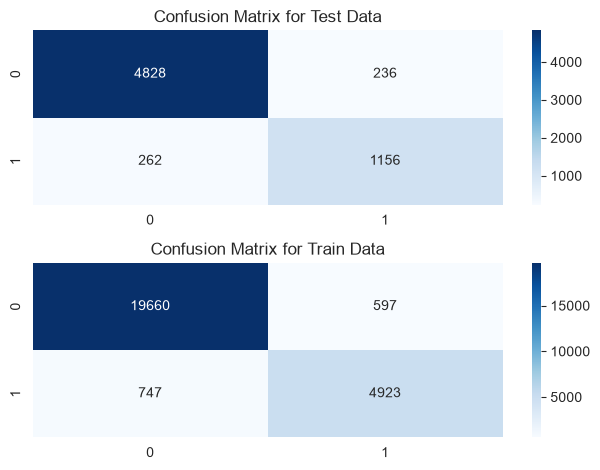

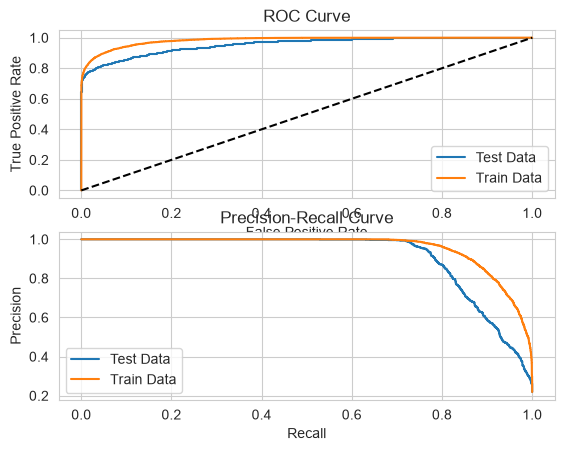




Classification Report for Test Data
              precision    recall  f1-score   support

           0       0.95      0.95      0.95      5064
           1       0.83      0.82      0.82      1418

    accuracy                           0.92      6482
   macro avg       0.89      0.88      0.89      6482
weighted avg       0.92      0.92      0.92      6482


Classification Report for Train Data
              precision    recall  f1-score   support

           0       0.96      0.97      0.97     20257
           1       0.89      0.87      0.88      5670

    accuracy                           0.95     25927
   macro avg       0.93      0.92      0.92     25927
weighted avg       0.95      0.95      0.95     25927






,XGBoast
Metric,
Accuracy_test,0.923172
Precision_test,0.830460
Recall_test,0.815233
F1 Score_test,0.822776
ROC-AUC_test,0.884315
Accuracy_train,0.948162
Precision_train,0.891848
Recall_train,0.868254
F1 Score_train,0.879893


In [55]:
metrics_xgb, xgb_model_classifier = evaluate_model(
    model_name = 'XGBoast',
    estimator = xgb_model,
    training_features = X_train,
    training_labels = y_train,
    testing_features = X_test,
    testing_labels = y_test,
    param_grid = param_grid,
    cv = 5
)

In [56]:
from sklearn.ensemble import RandomForestClassifier
rf = RandomForestClassifier(random_state = 44, class_weight = 'balanced', n_jobs = -1)

rf_model = Pipeline(steps = [
    ('Preprocessor' , preprocessor_xgb),
    ('Classifier', rf),
])

In [57]:
param_grid_rf = {
    'Classifier__n_estimators': [100, 200, 300],
    'Classifier__max_depth': [3, 4, 5, 6, 7],
    'Classifier__min_samples_split': [2, 5, 10],
    'Classifier__min_samples_leaf': [1, 2, 4],
    'Classifier__max_features': ['sqrt', 'log2', None]
}

Model: Random Forest
Fitting 5 folds for each of 10 candidates, totalling 50 fits
Best Parameters: {'Classifier__n_estimators': 200, 'Classifier__min_samples_split': 10, 'Classifier__min_samples_leaf': 1, 'Classifier__max_features': None, 'Classifier__max_depth': 7}
Best Score: 0.9152261141335689





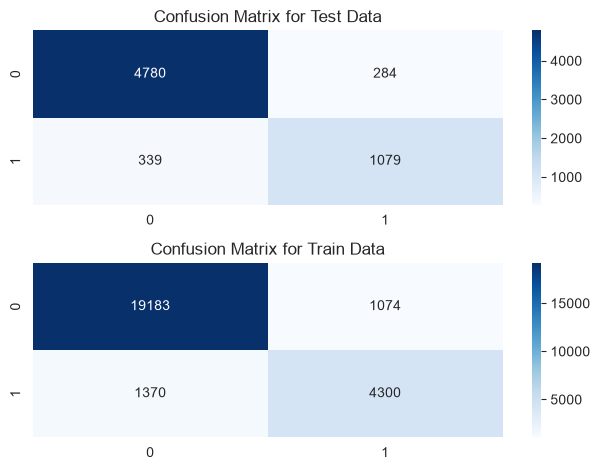

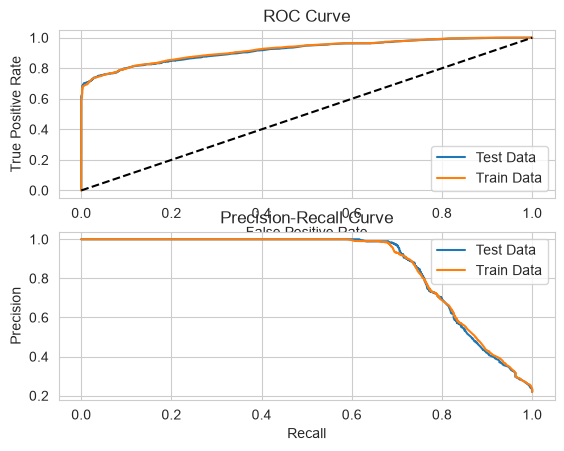




Classification Report for Test Data
              precision    recall  f1-score   support

           0       0.93      0.94      0.94      5064
           1       0.79      0.76      0.78      1418

    accuracy                           0.90      6482
   macro avg       0.86      0.85      0.86      6482
weighted avg       0.90      0.90      0.90      6482


Classification Report for Train Data
              precision    recall  f1-score   support

           0       0.93      0.95      0.94     20257
           1       0.80      0.76      0.78      5670

    accuracy                           0.91     25927
   macro avg       0.87      0.85      0.86     25927
weighted avg       0.90      0.91      0.90     25927






,Random Forest
Metric,
Accuracy_test,0.903888
Precision_test,0.791636
Recall_test,0.760931
F1 Score_test,0.775980
ROC-AUC_test,0.852424
Accuracy_train,0.905735
Precision_train,0.800149
Recall_train,0.758377
F1 Score_train,0.778703


In [58]:
metric_rf, rf_model = evaluate_model(
    model_name = 'Random Forest',
    estimator = rf_model,
    training_features = X_train,
    training_labels = y_train,
    testing_features = X_test,
    testing_labels = y_test,
    param_grid = param_grid_rf,
    cv = 5
)

In [59]:
def prediction(model):
  real = pd.DataFrame(X_test.sample(random_state = np.random.randint(1, 100)).values, columns = X_train.columns)
  real_status = y_test.sample(random_state = np.random.randint(1, 100)).values[0]

  if model.predict(real)[0] == real_status:
    print(f'Prediction is correct, ({model.predict(real)[0]}) while real prediction is {real_status}')
  else:
    print('Prediction is wrong')

In [60]:
print('Logistic Reggression')
print()
prediction(model_lr)
prediction(model_lr)
prediction(model_lr)
print('\n\n')
print('XGBoast')
print()
prediction(xgb_model_classifier)
prediction(xgb_model_classifier)
prediction(xgb_model_classifier)
print('\n\n')
print('Random Forest')
print()
prediction(rf_model)
prediction(rf_model)
prediction(rf_model)
print('\n\n')


Logistic Reggression

Prediction is wrong
Prediction is correct, (0) while real prediction is 0
Prediction is correct, (0) while real prediction is 0



XGBoast

Prediction is wrong
Prediction is correct, (1) while real prediction is 1
Prediction is correct, (0) while real prediction is 0



Random Forest

Prediction is correct, (0) while real prediction is 0
Prediction is wrong
Prediction is wrong





## Compare Both **LR XGB Model & Random Forest** Side by Side

In [61]:
df_compare = pd.concat([metrics_lr, metrics_xgb, metric_rf], axis = 1)
df_compare

,Logistic Regression,XGBoast,Random Forest
Metric,,,
Accuracy_test,0.806078,0.923172,0.903888
Precision_test,0.538572,0.830460,0.791636
Recall_test,0.792666,0.815233,0.760931
F1 Score_test,0.641369,0.822776,0.775980
ROC-AUC_test,0.801250,0.884315,0.852424
Accuracy_train,0.812203,0.948162,0.905735
Precision_train,0.549099,0.891848,0.800149
Recall_train,0.789947,0.868254,0.758377
F1 Score_train,0.647863,0.879893,0.778703


## Optimizing the **Classification Threshold**

In [62]:
prob = xgb_model_classifier.predict_proba(X_test)[:, 1]
pricision, recall, threshold = precision_recall_curve(y_test, prob)
f1 = 2 * (pricision * recall) / (pricision + recall)
best = np.argmax(f1[:-1])
best_threshold = threshold[best]
best_threshold

np.float32(0.6396822)

Model: XGBoast
Fitting 5 folds for each of 10 candidates, totalling 50 fits
Best Parameters: {'Classifier__subsample': 0.8, 'Classifier__n_estimators': 500, 'Classifier__min_child_weight': 1, 'Classifier__max_depth': 6, 'Classifier__learning_rate': 0.03, 'Classifier__gamma': 0.1, 'Classifier__colsample_bytree': 0.8}
Best Score: 0.9486550618811987





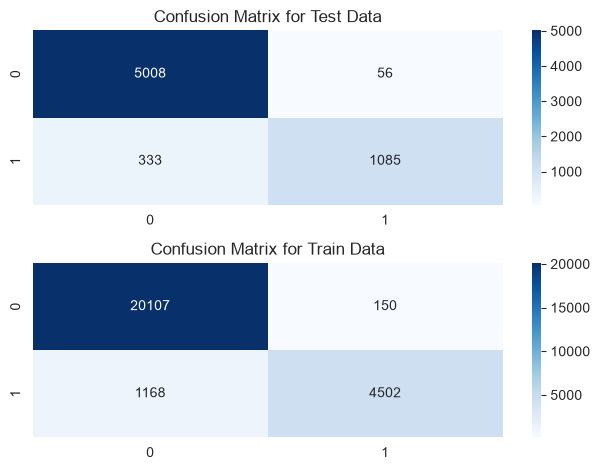

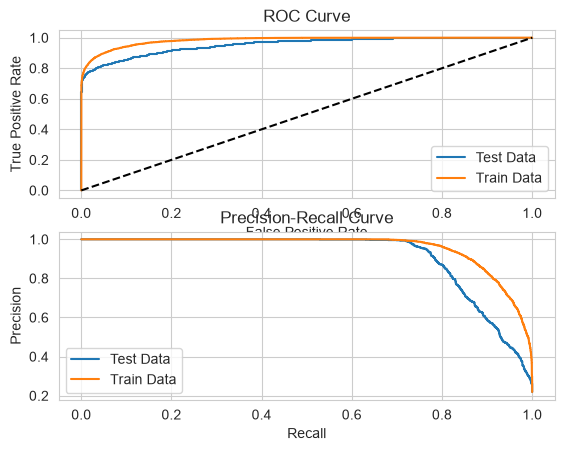




Classification Report for Test Data
              precision    recall  f1-score   support

           0       0.94      0.99      0.96      5064
           1       0.95      0.77      0.85      1418

    accuracy                           0.94      6482
   macro avg       0.94      0.88      0.91      6482
weighted avg       0.94      0.94      0.94      6482


Classification Report for Train Data
              precision    recall  f1-score   support

           0       0.95      0.99      0.97     20257
           1       0.97      0.79      0.87      5670

    accuracy                           0.95     25927
   macro avg       0.96      0.89      0.92     25927
weighted avg       0.95      0.95      0.95     25927






,XGBoast
Metric,
Accuracy_test,0.939988
Precision_test,0.950920
Recall_test,0.765162
F1 Score_test,0.847987
ROC-AUC_test,0.877052
Accuracy_train,0.949165
Precision_train,0.967756
Recall_train,0.794004
F1 Score_train,0.872312


In [63]:
metrics_xgb_thr, xgb_model_theresholded = evaluate_model(
    model_name = 'XGBoast',
    estimator = xgb_model,
    training_features = X_train,
    training_labels = y_train,
    testing_features = X_test,
    testing_labels = y_test,
    threshould = best_threshold,
    param_grid = param_grid,
    cv = 5
)

## **Probability Calibration**

In [64]:
from sklearn.calibration import CalibratedClassifierCV, calibration_curve

xgb_best = XGBClassifier(
    random_state = 44,
    scale_pos_weight = scale_weights,
    subsample = 1.0,
    n_estimators = 300,
    min_child_weight = 5,
    max_depth = 8,
    learning_rate = 0.1,
    gamma = 0,
    colsample_bytree = 0.6
)

xgb_model_best = Pipeline(steps = [
    ('Preprocessor' , preprocessor_xgb),
    ('Classifier', xgb_best)
])

model = CalibratedClassifierCV(
    xgb_model_best,
    method = 'isotonic',
    cv = 5
)

model.fit(X_train, y_train)

,"estimator estimator: estimator instance, default=NoneThe classifier whose output need to be calibrated to provide moreaccurate `predict_proba` outputs. The default classifier isa :class:`~sklearn.svm.LinearSVC`... versionadded:: 1.2","Pipeline(step...=None, ...))])"
,"method method: {'sigmoid', 'isotonic', 'temperature'}, default='sigmoid'The method to use for calibration. Can be:- 'sigmoid', which corresponds to Platt's method (i.e. a binary logistic regression model).- 'isotonic', which is a non-parametric approach.- 'temperature', temperature scaling.Sigmoid and isotonic calibration methods natively support only binaryclassifiers and extend to multi-class classification using a One-vs-Rest (OvR)strategy with post-hoc renormalization, i.e., adjusting the probabilities aftercalibration to ensure they sum up to 1.In contrast, temperature scaling naturally supports multi-class calibration byapplying `softmax(classifier_logits/T)` with a value of `T` (temperature)that optimizes the log loss.For very uncalibrated classifiers on very imbalanced datasets, sigmoidcalibration might be preferred because it fits an additional interceptparameter. This helps shift decision boundaries appropriately when theclassifier being calibrated is biased towards the majority class.Isotonic calibration is not recommended when the number of calibration samplesis too low ``(≪1000)`` since it then tends to overfit... versionchanged:: 1.8 Added option 'temperature'.",'isotonic'
,"cv cv: int, cross-validation generator, or iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross-validation,- integer, to specify the number of folds,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if ``y`` is binary or multiclass,:class:`~sklearn.model_selection.StratifiedKFold` is used. If ``y`` isneither binary nor multiclass, :class:`~sklearn.model_selection.KFold`is used.Refer to the :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors.Base estimator clones are fitted in parallel across cross-validationiterations.See :term:`Glossary <n_jobs>` for more details... versionadded:: 0.24",None
,"ensemble ensemble: bool, or ""auto"", default=""auto""Determines how the calibrator is fitted.""auto"" will use `False` if the `estimator` is a:class:`~sklearn.frozen.FrozenEstimator`, and `True` otherwise.If `True`, the `estimator` is fitted using training data, andcalibrated using testing data, for each `cv` fold. The final estimatoris an ensemble of `n_cv` fitted classifier and calibrator pairs, where`n_cv` is the number of cross-validation folds. The output is theaverage predicted probabilities of all pairs.If `False`, `cv` is used to compute unbiased predictions, via:func:`~sklearn.model_selection.cross_val_predict`, which are thenused for calibration. At prediction time, the classifier used is the`estimator` trained on all the data.Note that this method is also internally implemented in:mod:`sklearn.svm` estimators with the `probabilities=True` parameter... versionadded:: 0.24.. versionchanged:: 1.6 `""auto""` option is added and is the default.",'auto'
Name,Type,Value
"calibrated_classifiers_ calibrated_classifiers_: list (len() equal to cv or 1 if `ensemble=False`)The list of classifier and calibrator pairs.- When `ensemble=True`, `n_cv` fitted `estimator` and calibrator pairs. `n_cv` is the number of cross-validation folds.- When `ensemble=False`, the `estimator`, fitted on all the data, and fitted calibrator... versionchanged:: 0.24 Single calibrated classifier case when `ensemble=False`.",list,"[<sklearn.cali...001B615D601A0>, 

In [65]:
uncalibrated_prob = xgb_model_classifier.predict_proba(X_test)[:, 1]
calibrated_prob = model.predict_proba(X_test)[:, 1]

In [66]:
actual_uncalibrated, prob_uncalibrated = calibration_curve(y_test, uncalibrated_prob, n_bins = 10)
actual_calibrated, prob_calibrated = calibration_curve(y_test, calibrated_prob, n_bins = 10)

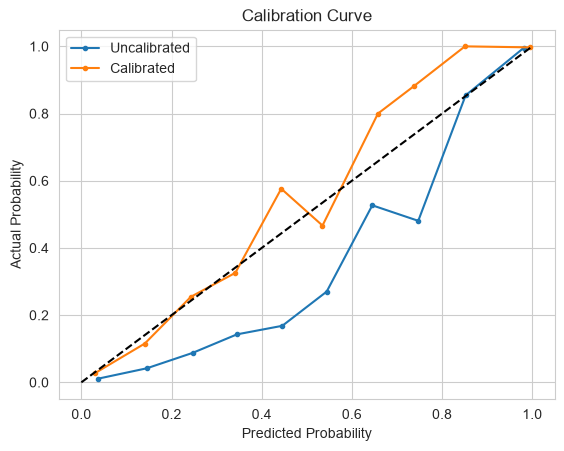

In [67]:
plt.plot(
    prob_uncalibrated,
    actual_uncalibrated,
    marker = '.',
    label = 'Uncalibrated'
)
plt.plot(
    prob_calibrated,
    actual_calibrated,
    marker = '.',
    label = 'Calibrated'
)
plt.plot([0, 1], [0, 1], linestyle = '--', color = 'black')
plt.xlabel('Predicted Probability')
plt.ylabel('Actual Probability')
plt.title('Calibration Curve')
plt.legend()
plt.show()

In [68]:
df_compare['XGBoast_Thresholded'] = metrics_xgb_thr
df_compare

,Logistic Regression,XGBoast,Random Forest,XGBoast_Thresholded
Metric,,,,
Accuracy_test,0.806078,0.923172,0.903888,0.939988
Precision_test,0.538572,0.830460,0.791636,0.950920
Recall_test,0.792666,0.815233,0.760931,0.765162
F1 Score_test,0.641369,0.822776,0.775980,0.847987
ROC-AUC_test,0.801250,0.884315,0.852424,0.877052
Accuracy_train,0.812203,0.948162,0.905735,0.949165
Precision_train,0.549099,0.891848,0.800149,0.967756
Recall_train,0.789947,0.868254,0.758377,0.794004
F1 Score_train,0.647863,0.879893,0.778703,0.872312


## Analyzing **False Psitive** & **False Negative** - **Model Evaluation**

In [69]:
def prediction(model, nop = 10):
  for i in range(nop):
    random_val = np.random.randint(1, 100)
    real = pd.DataFrame(X_test.sample(random_state = random_val).values, columns = X_train.columns)
    real_status = y_test.sample(random_state = random_val).values[0]

    pred = model.predict_proba(real)[:, 1]
    if pred >= best_threshold:
      pred = 1
    else:
      pred = 0

    if pred == real_status:
      print(f'{i + 1}. Prediction is correct, ({pred}) while real prediction is {real_status}')
    else:
      print(f'{i + 1}. Prediction is wrong')

In [70]:
print("Model Predictions sample")
prediction(model, nop = 100)

Model Predictions sample
1. Prediction is correct, (1) while real prediction is 1
2. Prediction is correct, (1) while real prediction is 1
3. Prediction is correct, (1) while real prediction is 1
4. Prediction is correct, (0) while real prediction is 0
5. Prediction is correct, (1) while real prediction is 1
6. Prediction is correct, (0) while real prediction is 0
7. Prediction is correct, (0) while real prediction is 0
8. Prediction is correct, (0) while real prediction is 0
9. Prediction is correct, (0) while real prediction is 0
10. Prediction is correct, (0) while real prediction is 0
11. Prediction is wrong
12. Prediction is correct, (1) while real prediction is 1
13. Prediction is correct, (0) while real prediction is 0
14. Prediction is correct, (0) while real prediction is 0
15. Prediction is correct, (0) while real prediction is 0
16. Prediction is correct, (0) while real prediction is 0
17. Prediction is correct, (1) while real prediction is 1
18. Prediction is correct, (0) w

In [71]:
print("XGB thresh model prediction sample")
prediction(xgb_model_theresholded, nop = 100)

XGB thresh model prediction sample
1. Prediction is correct, (0) while real prediction is 0
2. Prediction is correct, (0) while real prediction is 0
3. Prediction is correct, (0) while real prediction is 0
4. Prediction is correct, (1) while real prediction is 1
5. Prediction is wrong
6. Prediction is correct, (1) while real prediction is 1
7. Prediction is correct, (0) while real prediction is 0
8. Prediction is correct, (1) while real prediction is 1
9. Prediction is correct, (0) while real prediction is 0
10. Prediction is correct, (0) while real prediction is 0
11. Prediction is correct, (0) while real prediction is 0
12. Prediction is correct, (0) while real prediction is 0
13. Prediction is correct, (0) while real prediction is 0
14. Prediction is correct, (0) while real prediction is 0
15. Prediction is correct, (0) while real prediction is 0
16. Prediction is correct, (0) while real prediction is 0
17. Prediction is correct, (0) while real prediction is 0
18. Prediction is corr

In [72]:
pred_prob = xgb_model_theresholded.predict_proba(X_test)[:, 1]
pred_test = (pred_prob >= best_threshold).astype(int)

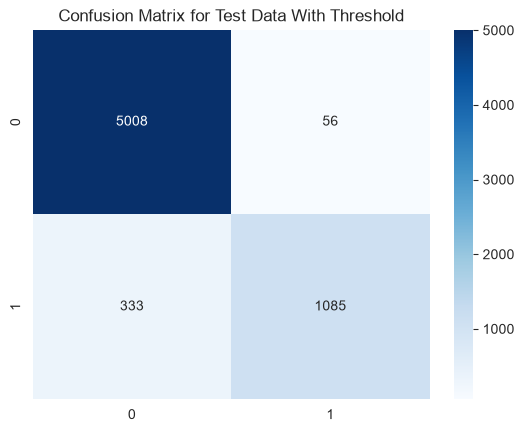

In [73]:
sns.heatmap(confusion_matrix(y_test, pred_test), annot = True, fmt = 'd', cmap = 'Blues')
plt.title('Confusion Matrix for Test Data With Threshold')
plt.show()

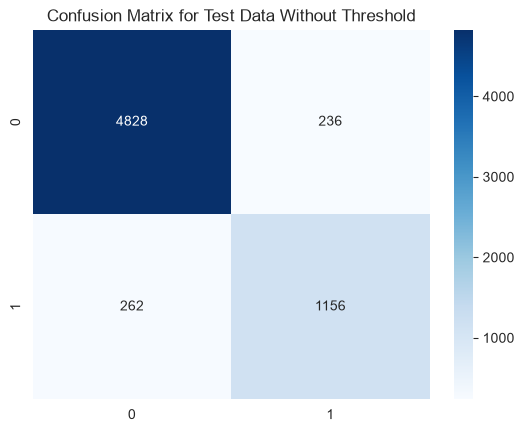

In [74]:
sns.heatmap(confusion_matrix(y_test, xgb_model_classifier.predict(X_test)), annot = True, fmt = 'd', cmap = 'Blues')
plt.title('Confusion Matrix for Test Data Without Threshold')
plt.show()

### Winner Model **xgb_model_classifier**

## Export the **Final Model**

In [75]:
import joblib
joblib.dump(xgb_model_classifier, '../server/model/credit_risk_model.pkl')

['../server/model/credit_risk_model.pkl']